# 3. Clasificación
Objetivo: predecir la situación final del estudiante (Abandono / Matriculado / Graduado) y comparar varios modelos supervisados, uno lineal (Logistic Regression) y dos no lineales basados en árboles (Random Forest y Gradient Boosting). Se utilizan todas las variables del dataset, incluidas las del segundo semestre, por lo que el modelo relaciona el rendimiento observado durante el primer año con el desenlace final; no es un sistema de alerta temprana.

### Imports y carga de datos

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os

from sklearn.metrics import classification_report, confusion_matrix, f1_score, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.inspection import permutation_importance

os.makedirs('../models', exist_ok=True)
os.makedirs('../predictions', exist_ok=True)

df = pd.read_csv('../rendimiento_estudiantes.csv', sep=';')
X = df.drop(columns=['objetivo'])
y = df['objetivo']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0, stratify=y)

preprocessor = joblib.load('../preprocessors/preprocessor_clf.pkl')
X_train_t = preprocessor.transform(X_train)
X_test_t  = preprocessor.transform(X_test)

le = joblib.load('../preprocessors/label_encoder_target.pkl')
y_train_enc = le.transform(y_train)
y_test_enc  = le.transform(y_test)

print(f'Train: {X_train_t.shape[0]} instancias | Test: {X_test_t.shape[0]} instancias')

clases = le.classes_
print('Clases:', clases)

Train: 3539 instancias | Test: 885 instancias
Clases: ['abandono' 'graduado' 'matriculado']


### Definición de modelos
Se comparan tres modelos con diferentes grados de complejidad:

- **Logistic Regression**: clasificador lineal base que modela la probabilidad de cada clase mediante una función sigmoide. Se usa class_weight='balanced' para compensar el desbalanceo entre clases y max_iter=1000 para asegurar la convergencia.
- **Random Forest**: modelo no lineal basado en un ensemble de árboles de decisión entrenados en paralelo (bagging). Captura relaciones complejas entre variables y es robusto frente al ruido. Se usa class_weight='balanced' por el mismo motivo que en LogReg.
- **Gradient Boosting**: ensemble de árboles entrenados en secuencia, donde cada árbol corrige los errores del anterior (boosting). Suele ofrecer mayor precisión que Random Forest a costa de mayor tiempo de entrenamiento. No admite `class_weight` (habría que pasar `sample_weight` al entrenar), así que aquí se entrena sin compensar el desbalanceo entre clases.

In [2]:
modelos = {
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=0),
    'Random Forest': RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=0),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, random_state=0)
}

print('Modelos:')
for i, m in modelos.items():
    print(f'{i}   \t-> {m}')

Modelos:
Logistic Regression   	-> LogisticRegression(class_weight='balanced', max_iter=1000, random_state=0)
Random Forest   	-> RandomForestClassifier(class_weight='balanced', random_state=0)
Gradient Boosting   	-> GradientBoostingClassifier(random_state=0)


### Entrenamiento y evaluación
En este apartado se entrena los tres modelos, y se evalúa sus resultados al predecir el set de test. Se sacan las siguientes medidas:

**Precision:** proporción de instancias predecidas como clase X que realmente son clase X

**Recall:** proporción de instancias de la clase X que han sido predecidas como clase X

**F1-score:** media armónica entre precision y recall

**Accuracy:** proporción de predicciones correctas sobre el total, sin distinguir clase

**Macro avg:** media de precision/recall/F1 de cada clase dando el mismo peso a todas

**Weighted avg:** media de precision/recall/F1 de cada clase ponderando por numero de instancias

In [3]:
resultados = {}

for nombre, modelo in modelos.items():
    modelo.fit(X_train_t, y_train_enc)
    y_pred = modelo.predict(X_test_t)
    f1_macro = f1_score(y_test_enc, y_pred, average='macro')
    resultados[nombre] = {'modelo': modelo, 'y_pred': y_pred, 'f1_macro': f1_macro}
    print(f'- {nombre} -')
    print(classification_report(y_test_enc, y_pred, target_names=clases))


- Logistic Regression -
              precision    recall  f1-score   support

    abandono       0.85      0.77      0.81       284
    graduado       0.85      0.80      0.82       442
 matriculado       0.46      0.62      0.53       159

    accuracy                           0.76       885
   macro avg       0.72      0.73      0.72       885
weighted avg       0.78      0.76      0.77       885

- Random Forest -
              precision    recall  f1-score   support

    abandono       0.81      0.76      0.79       284
    graduado       0.78      0.95      0.86       442
 matriculado       0.61      0.30      0.40       159

    accuracy                           0.78       885
   macro avg       0.73      0.67      0.68       885
weighted avg       0.76      0.78      0.75       885

- Gradient Boosting -
              precision    recall  f1-score   support

    abandono       0.82      0.77      0.79       284
    graduado       0.80      0.92      0.86       442
 matriculad

> Logistic Regression rinde muy bien en 'abandono' y 'graduado', con buen precision y recall. Predice 'matriculado' peor, pero tiene buen recall.

> Random Forest y Gradient Boosting ofrecen resultados parecidos. Fuertes en 'graduado', pero peores en 'matriculado'. Claramente tienen problema con la clase minoritaria.

### Comparación de modelos

Se comparan los modelos por Macro F1. El Macro F1 es la medida más importante, ya que penaliza por igual si el modelo falla en cualquier clase independientemente de cuántos casos tenga.

                Modelo  Macro F1
0  Logistic Regression  0.721736
1        Random Forest  0.683789
2    Gradient Boosting  0.690969


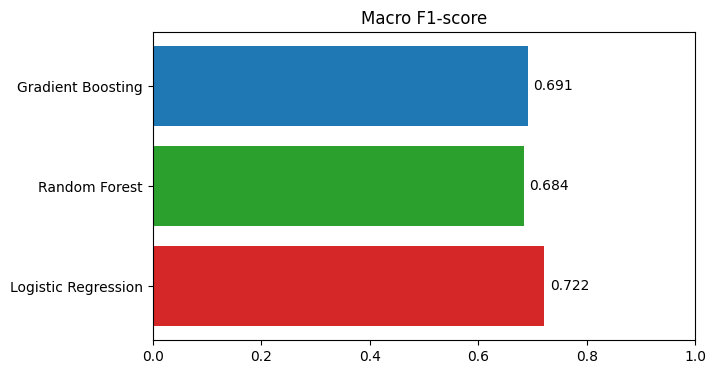

In [4]:
comparacion = pd.DataFrame({
    'Modelo': list(resultados.keys()),
    'Macro F1': [v['f1_macro'] for v in resultados.values()]
})

print(comparacion)

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.barh(comparacion['Modelo'], comparacion['Macro F1'], color=['tab:red', 'tab:green', 'tab:blue'])
ax.set_xlim(0, 1)
ax.set_title('Macro F1-score')
for bar, val in zip(bars, comparacion['Macro F1']):
    ax.text(val + 0.01, bar.get_y() + bar.get_height()/2, f'{val:.3f}', va='center')

> Como era de esperar, Logistic Regression es el mejor modelo teniendo en cuenta Macro F1, con RF y GB muy igualados detrás. 

### Matrices de confusión
Permiten ver qué clases confunde cada modelo. Especialmente relevante para la clase minoritaria (Matriculado).

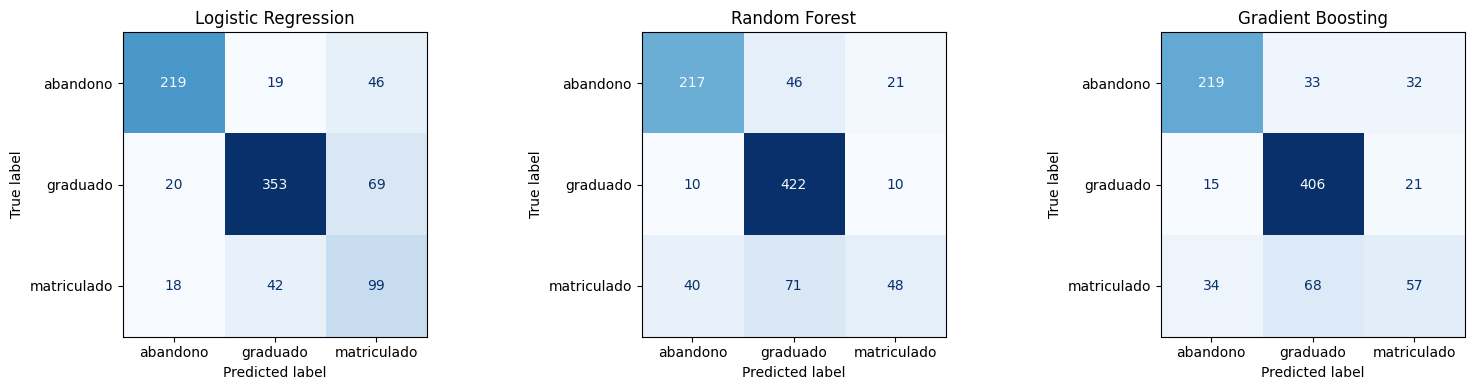

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, (nombre, vals) in zip(axes, resultados.items()):
    cm = confusion_matrix(y_test_enc, vals['y_pred'])
    disp = ConfusionMatrixDisplay(cm, display_labels=clases)
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(nombre)

plt.tight_layout()
plt.show()

> Al ser 'matriculado' la clase menos poblada, todos los modelos tienen problemas con ella. LogReg lo hace ligeramente mejor, pero los resultados no son muy buenos. De hecho, con LogReg, una predicción de 'matriculado' tiene más probabilidades de ser incorrecta que correcta.

### Importancia de variables
Analizamos qué variables son más determinantes en cada modelo. Esto conecta directamente con las preguntas del enunciado: ¿qué factores se asocian con el abandono?

- Logistic Regression -
Sin feature_importances_ — calculando Permutation Importance...


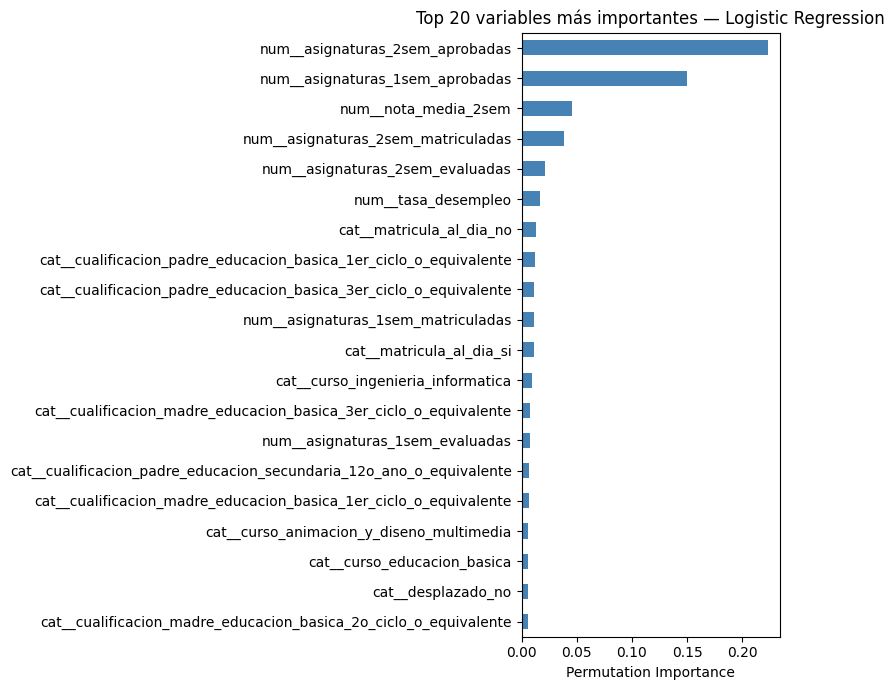

- Random Forest -


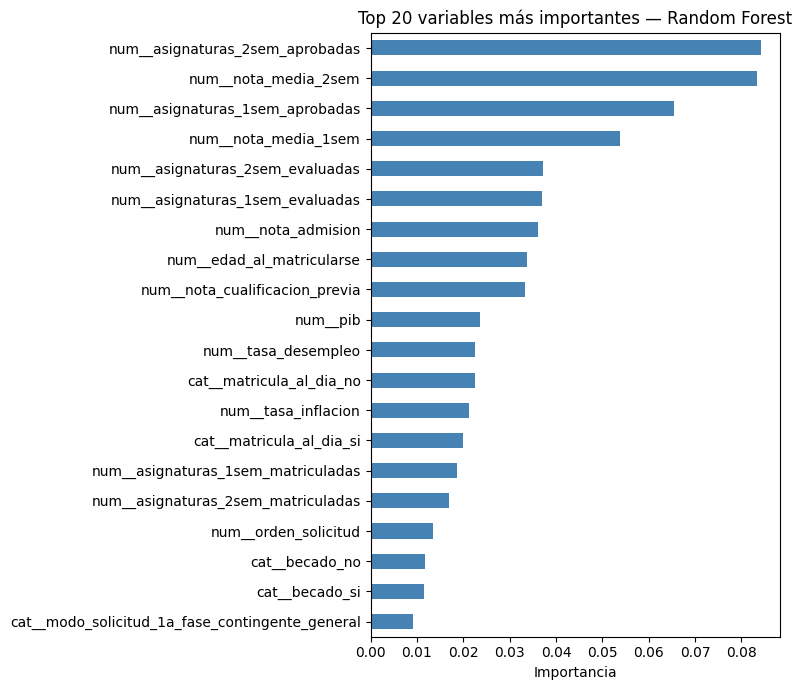

- Gradient Boosting -


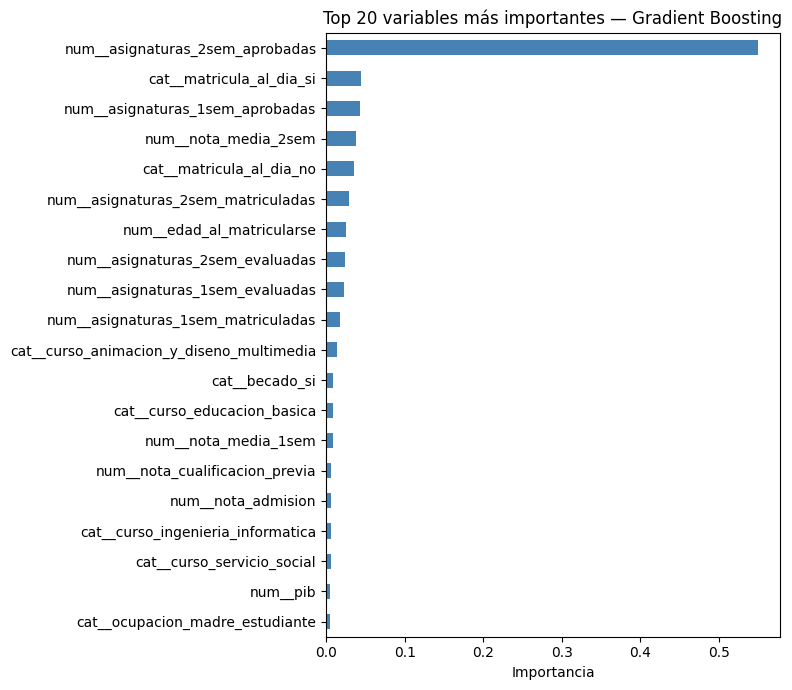

In [6]:
for nombre, modelo in modelos.items():
    print(f'- {nombre} -')
    feature_names = preprocessor.get_feature_names_out()

    if hasattr(modelo, 'feature_importances_'):
        importancias = pd.Series(modelo.feature_importances_, index=feature_names)
        label_x = 'Importancia'
    else:
        print('Sin feature_importances_ — calculando Permutation Importance...')
        result = permutation_importance(modelo, X_test_t, y_test_enc, n_repeats=10, random_state=0, n_jobs=-1)
        importancias = pd.Series(result.importances_mean, index=feature_names)
        label_x = 'Permutation Importance'

    top20 = importancias.sort_values(ascending=False).head(20)

    fig, ax = plt.subplots(figsize=(8, 7))
    top20.sort_values().plot(kind='barh', ax=ax, color='steelblue')
    ax.set_title(f'Top 20 variables más importantes — {nombre}')
    ax.set_xlabel(label_x)
    plt.tight_layout()
    plt.show()

> La Permutation Importance mide la importancia de cada variable barajando aleatoriamente sus valores en el conjunto de test y evaluando cuánto empeora el rendimiento del modelo. Si al permutar una variable el error aumenta significativamente, la variable es importante; si el error apenas cambia, el modelo no dependía de ella. Se usa en este caso para Logistic Regression porque este modelo no almacena feature_importances

> Salen los resultados esperados. Las variables que más contribuyen a si un alumno se gradúa o abandona la carrera es si aprueba asignaturas, su nota media, etc., en general cosas relacionadas a sus estudios. Es destacable que, para RF, hay varias variables con alta importancia, pero para GB prácticamente la única es el número de asignaturas aprobadas en el 2º semestre. LogReg es un caso diferente a los otros dos, pero sigue las mismas tendencias que los árboles

### Guardar modelos y predicciones
Se guardan los tres modelos utilizados y los tres ficheros de predicciones para poder acceder a la información sin ejecutar este notebook.

In [7]:
# Guardar modelos
joblib.dump(modelos['Logistic Regression'], f'../models/logistic_regression.pkl')
joblib.dump(modelos['Random Forest'], f'../models/random_forest_clf.pkl')
joblib.dump(modelos['Gradient Boosting'], f'../models/gradient_boosting.pkl')


# Guardar predicciones
for nombre, vals in resultados.items():
    nombre_fichero = nombre.lower().replace(' ', '_')
    pred_df = pd.DataFrame({
        'y_real': le.inverse_transform(y_test_enc),
        'y_pred': le.inverse_transform(resultados[nombre]['y_pred'])
    })
    pred_df.to_csv(f'../predictions/pred_clasificacion_{nombre_fichero}.csv', index=False)